In [98]:
import pandas as pd
import sys
import os
import datetime as dt
from pathlib import Path
from sgp4.api import Satrec, WGS72, jday,SatrecArray
import math
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt

In [99]:
# Initialize the starting path (current directory)
base_path = Path('..')
#print(base_path)
# Find all items inside any 'dir1' folder exactly one level down
# and filter to keep only files
files_in_dir = [
    item for item in base_path.glob("*/orbcomm_9_10_2026/*") if item.is_file()
]
sat_data_array =[]
# Print the paths
for file in files_in_dir:
    sat_data = pd.read_csv(file)
    #print(sat_data)
    sat_data_array.append(sat_data)

In [111]:


# 1. Define standard gravitational parameter for SGP4's default WGS-72
# (Value: 398600.8 km^3/s^2)
MU = 398600.8

def rv_to_kepler(r, v, mu=MU):
    # Vector magnitudes
    r_mag = np.linalg.norm(r)
    v_mag = np.linalg.norm(v)

    # 1. Specific Angular Momentum (h)
    h = np.cross(r, v)
    h_mag = np.linalg.norm(h)

    # 2. Inclination (i) -> Angle between h and Z-axis
    i = np.arccos(h[2] / h_mag)

    # Node vector (n) -> Intersection of equatorial and orbital planes
    n = np.cross([0, 0, 1], h)
    n_mag = np.linalg.norm(n)

    # 3. Right Ascension of Ascending Node (Ω / RAAN)
    if n_mag != 0:
        RAAN = np.arccos(n[0] / n_mag)
        if n[1] < 0:
            RAAN = 2 * np.pi - RAAN
    else:
        RAAN = 0.0  # Equatorial orbit

    # Eccentricity vector (e)
    e_vec = ((v_mag**2 - mu / r_mag) * r - np.dot(r, v) * v) / mu
    # 4. Eccentricity (e)
    e = np.linalg.norm(e_vec)

    # 5. Argument of Perigee (ω)
    if n_mag != 0:
        if e > 1e-11:
            omega = np.arccos(np.dot(n, e_vec) / (n_mag * e))
            if e_vec[2] < 0:
                omega = 2 * np.pi - omega
        else:
            omega = 0.0
    else:
        omega = 0.0  # Equatorial orbit

    # 6. True Anomaly (ν)
    if e > 1e-11:
        true_anomaly = np.arccos(np.dot(e_vec, r) / (e * r_mag))
        if np.dot(r, v) < 0:
            true_anomaly = 2 * np.pi - true_anomaly
    else:
        # Circular orbit: use angle from node vector
        if n_mag != 0:
            true_anomaly = np.arccos(np.dot(n, r) / (n_mag * r_mag))
            if r[2] < 0:
                true_anomaly = 2 * np.pi - true_anomaly
        else:
            true_anomaly = np.arctan2(r[1], r[0])

    # Semi-major axis (a)
    energy = (v_mag**2 / 2.0) - (mu / r_mag)
    a = -mu / (2.0 * energy)

    return {
        "semi_major_axis_km": a,
        "eccentricity": e,
        "inclination_deg": np.degrees(i),
        "raan_deg": np.degrees(RAAN),
        "arg_perigee_deg": np.degrees(omega),
        "true_anomaly_deg": np.degrees(true_anomaly)
    }

# --- Example Usage with SGP4 ---
# ISS TLE Example
s = '1 25544U 98067A   19343.69339541  .00001764  00000-0  38792-4 0  9991'
t = '2 25544  51.6439 211.2001 0007417  17.6667  85.6398 15.50103472202482'
satellite = Satrec.twoline2rv(s, t)

# Propagate to get r and v
error_code, r, v = satellite.sgp4(2458826.5, 0.8625)

if error_code == 0:
    kepler_elements = rv_to_kepler(np.array(r), np.array(v))
    for param, val in kepler_elements.items():
        print(f"{param}: {val:.4f}")

semi_major_axis_km: 6797.5774
eccentricity: 0.0011
inclination_deg: 51.6523
raan_deg: 210.3388
arg_perigee_deg: 35.2297
true_anomaly_deg: 292.2286


In [101]:
# clean duplicates
sat_data_array_filt = sat_data_array.copy()

isat =0
for sat in sat_data_array:
    sat['r_init']=None
    sat['r_pred']=None
    sat['r_true']=None
    sat['v_init']=None
    sat['v_pred']=None
    sat['v_true']=None
    sat['time_utc']=None
    ind = np.zeros(len(sat))
    col_idx = sat.columns.get_loc('time_utc')
    sat_filtered= sat.copy()
    for i in range(len(sat)-1):

        date_i= sat_filtered.iloc[i].EPOCH
        date_ip1= sat_filtered.iloc[i+1].EPOCH
        time_i = dt.datetime.fromisoformat(date_i).replace(tzinfo=dt.timezone.utc)
        time_ip1 = dt.datetime.fromisoformat(date_ip1).replace(tzinfo=dt.timezone.utc)
        print(time_i, time_ip1)
        sat_filtered.iloc[i, col_idx] = time_i
        sat_filtered.iloc[i+1, col_idx] = time_ip1
        delta_time = time_ip1 - time_i
        delta_time_seconds = delta_time.total_seconds()
        if delta_time_seconds> 10:
            ind[i]=1
            ind[i+1]=1
        else:
            ind[i]=0
            ind[i+1]=1
    sat_filtered = sat_filtered[ind==1]
    #print(sat_filtered)
    sat_data_array_filt[isat]= sat_filtered
    isat = isat+1



2026-09-01 12:01:42.747744+00:00 2026-09-01 12:01:42.748608+00:00
2026-09-01 12:01:42.748608+00:00 2026-09-01 18:36:10.410336+00:00
2026-09-01 18:36:10.410336+00:00 2026-09-02 07:45:05.738976+00:00
2026-09-02 07:45:05.738976+00:00 2026-09-02 07:45:05.739840+00:00
2026-09-02 07:45:05.739840+00:00 2026-09-03 01:49:51.786912+00:00
2026-09-03 01:49:51.786912+00:00 2026-09-03 01:49:51.787776+00:00
2026-09-03 01:49:51.787776+00:00 2026-09-04 02:29:05.437824+00:00
2026-09-04 02:29:05.437824+00:00 2026-09-04 02:29:05.438688+00:00
2026-09-04 02:29:05.438688+00:00 2026-09-04 10:42:09.991872+00:00
2026-09-04 10:42:09.991872+00:00 2026-09-04 10:42:09.992736+00:00
2026-09-04 10:42:09.992736+00:00 2026-09-05 01:29:42.154080+00:00
2026-09-05 01:29:42.154080+00:00 2026-09-05 01:29:42.154944+00:00
2026-09-05 01:29:42.154944+00:00 2026-09-05 09:42:46.677888+00:00
2026-09-05 09:42:46.677888+00:00 2026-09-05 09:42:46.678752+00:00
2026-09-05 09:42:46.678752+00:00 2026-09-06 00:30:18.816768+00:00
2026-09-06

In [134]:
# perform sgp4 predictions
sat_data_array_aug =[]
for isat  in range(len(sat_data_array_filt)):

    sat = sat_data_array_filt[isat].copy()
    for irow in range(len(sat)-1):
        date_str_init = sat.iloc[irow].EPOCH
        date_str_pred = sat.iloc[irow+1].EPOCH
        sat_init_time = dt.datetime.fromisoformat(date_str_init).replace(tzinfo=dt.timezone.utc)
        sat_pred_time = dt.datetime.fromisoformat(date_str_pred).replace(tzinfo=dt.timezone.utc)
        epoch_1949 = dt.datetime(1949, 12, 31, 0, 0, tzinfo=dt.timezone.utc)
        delta_1949= sat_init_time - epoch_1949
        days_since_1949 = delta_1949.total_seconds() / 86400

        # 1. Parse mean motion derivatives correctly
        mm_dot = float(sat.iloc[irow].MEAN_MOTION_DOT)
        mm_ddot = float(sat.iloc[irow].MEAN_MOTION_DDOT)
        mm = float(sat.iloc[irow].MEAN_MOTION)
        # 2. Convert TLE/OMM units to SGP4 native units (Revolutions/Day -> Radians/Minute)
        # 2pi / 1440 min = 0.004363323129985824
        ndot = mm_dot * (2 * math.pi / (1440.0 ** 2))
        nddot = mm_ddot * (2 * math.pi / (1440.0 ** 3))
        no_kozai = mm * (2 * math.pi / 1440.0)

        sat_pred = Satrec()
        sat_pred.sgp4init(
        WGS72,
        'i',
        int(sat.iloc[irow].NORAD_CAT_ID),
        days_since_1949,
        sat.iloc[irow].BSTAR,
        ndot,        # Corrected unit
        nddot,       # Corrected unit
        sat.iloc[irow].ECCENTRICITY,
        math.radians(sat.iloc[irow].ARG_OF_PERICENTER),
        math.radians(sat.iloc[irow].INCLINATION),
        math.radians(sat.iloc[irow].MEAN_ANOMALY),
        no_kozai,    # Corrected unit
        math.radians(sat.iloc[irow].RA_OF_ASC_NODE),
    )
        jd_init, fr_init = jday(sat_init_time.year, sat_init_time.month, sat_init_time.day, sat_init_time.hour, sat_init_time.minute, sat_init_time.second)
        jd_pred, fr_pred = jday(sat_pred_time.year, sat_pred_time.month, sat_pred_time.day, sat_pred_time.hour, sat_pred_time.minute, sat_pred_time.second)
        e,r_init, v_init = sat_pred.sgp4(jd_init, fr_init)
        e,r_pred, v_pred = sat_pred.sgp4(jd_pred, fr_pred)


        row_label = sat.index[irow]

        sat.at[row_label, 'r_init'] = tuple(r_init)
        sat.at[row_label, 'v_init'] = tuple(v_init)
        sat.at[row_label, 'r_pred'] = tuple(r_pred)
        sat.at[row_label, 'v_pred'] = tuple(v_pred)
    sat_data_array_aug.append(sat)





/var/folders/5q/5g9j18hx215d622zpg6bd7mh0000gn/T/ipykernel_74129/2083358624.py:158: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig,ax= plt.subplots(3,2)


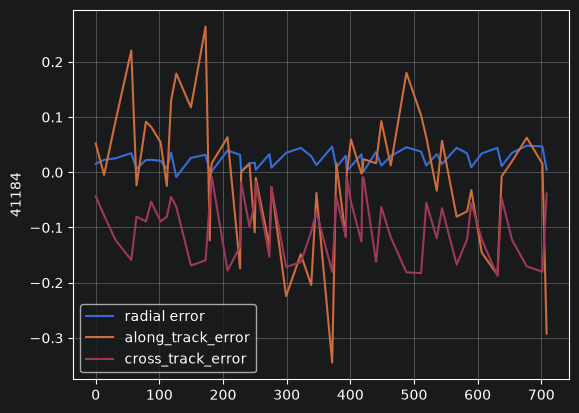

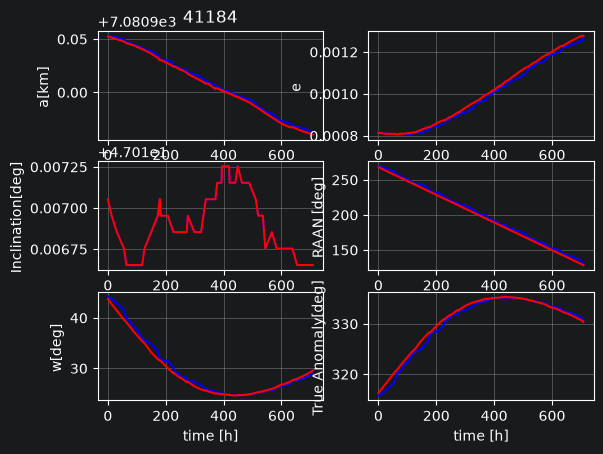

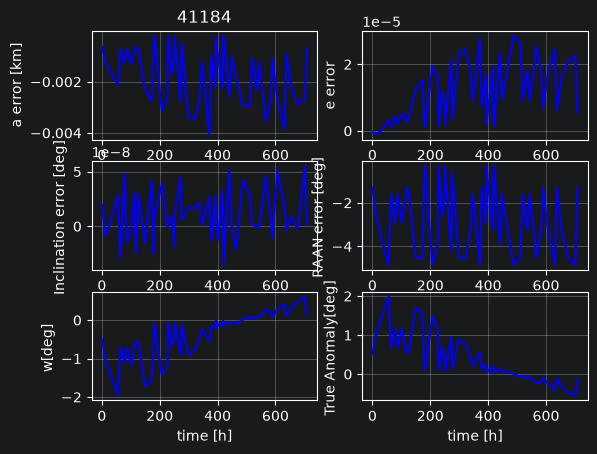

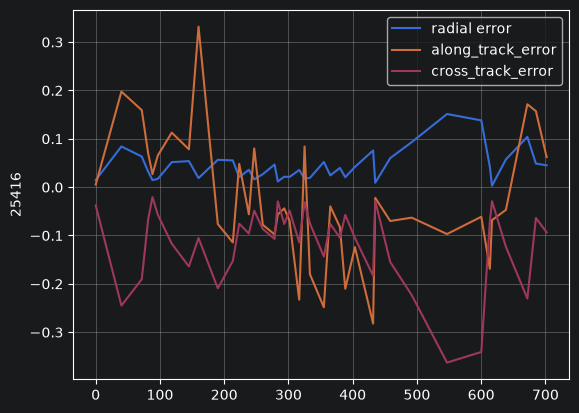

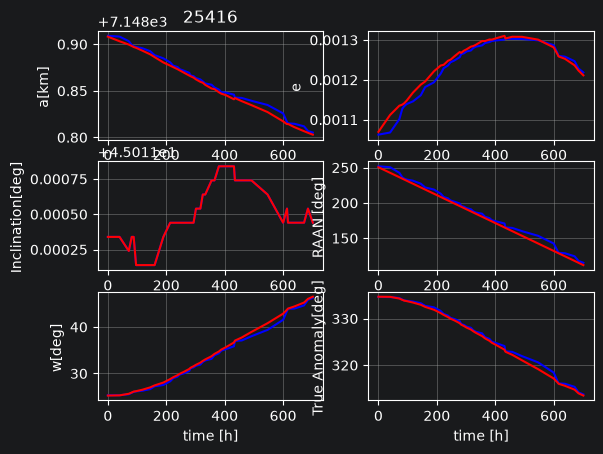

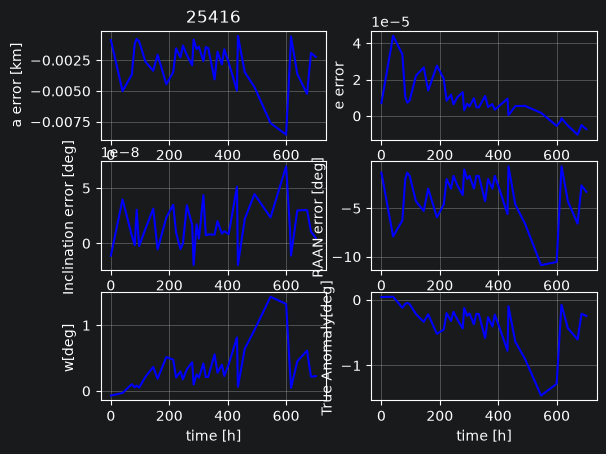

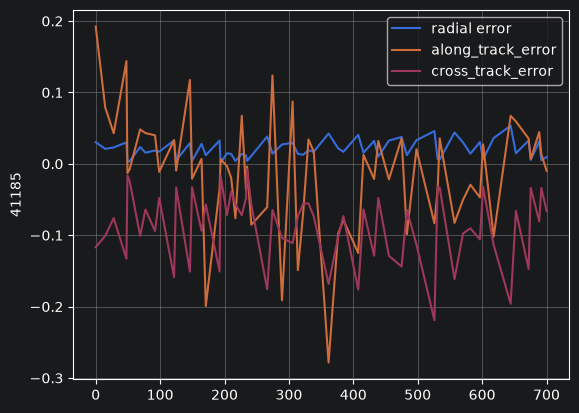

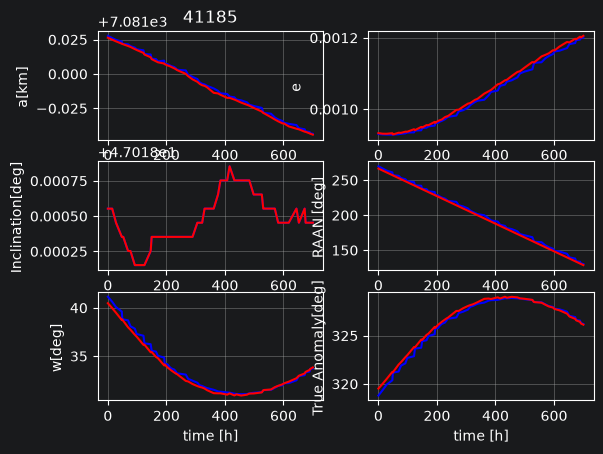

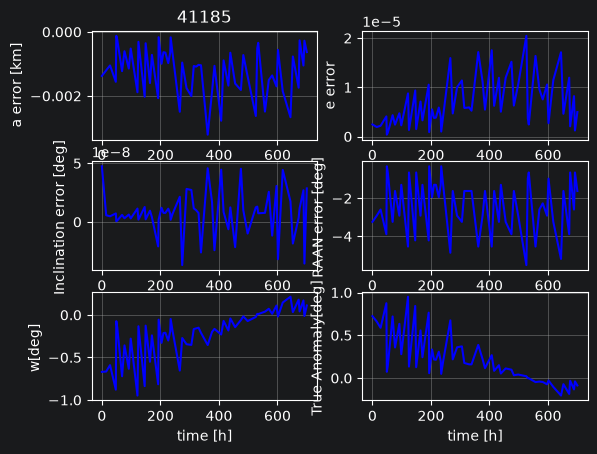

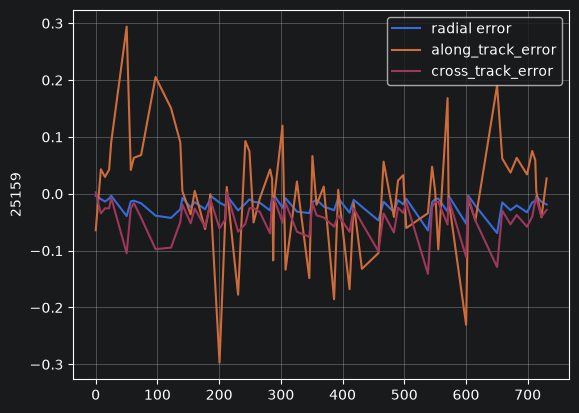

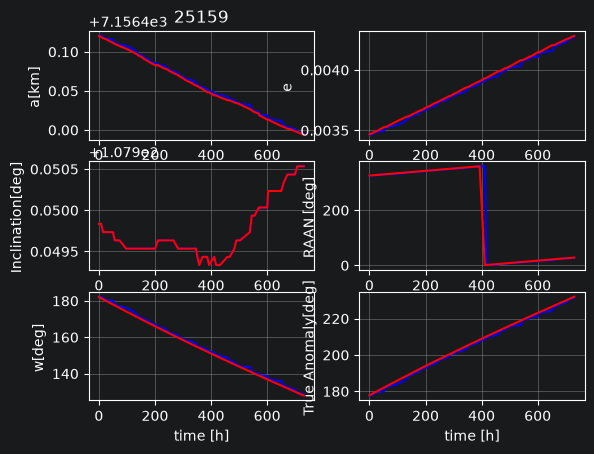

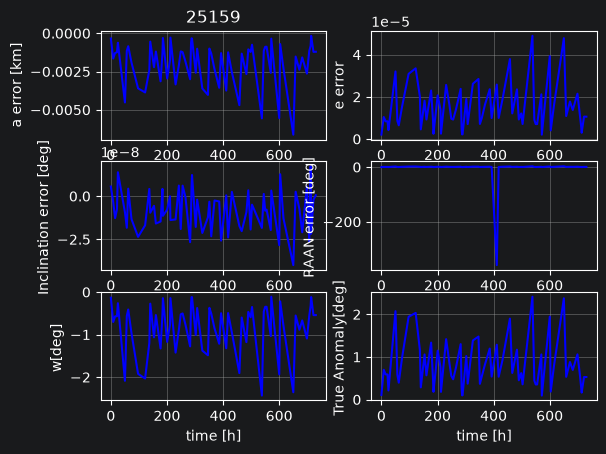

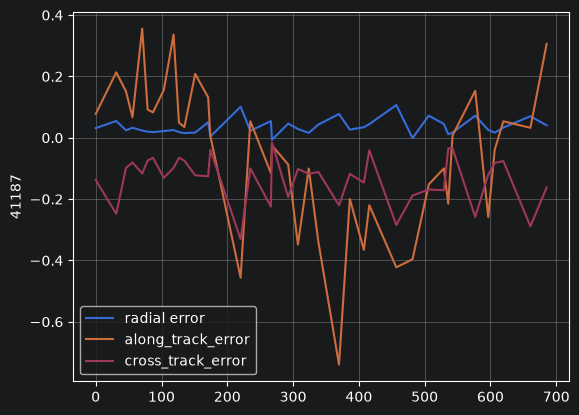

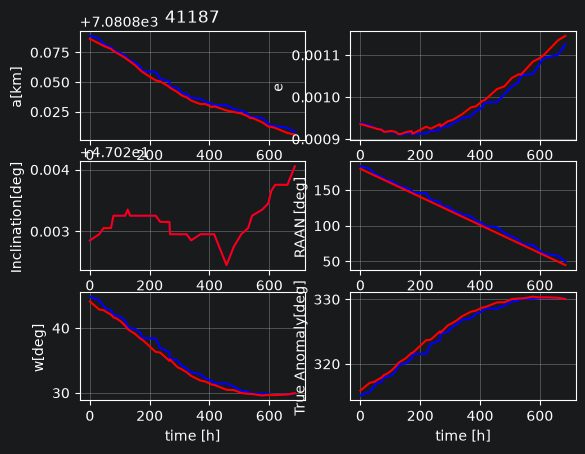

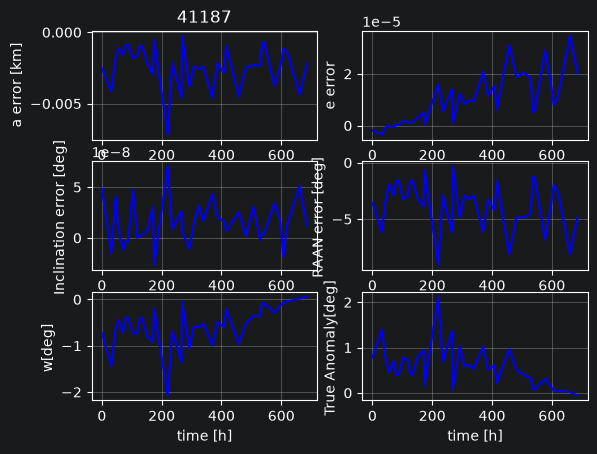

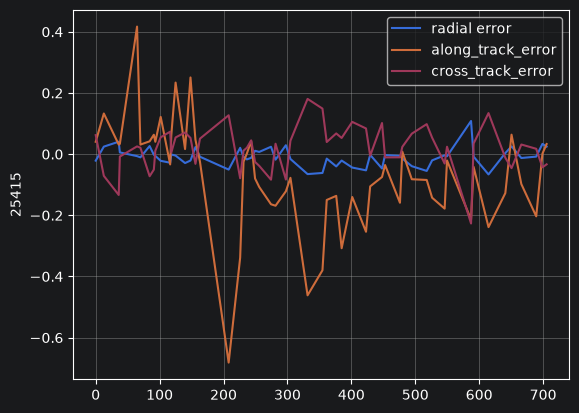

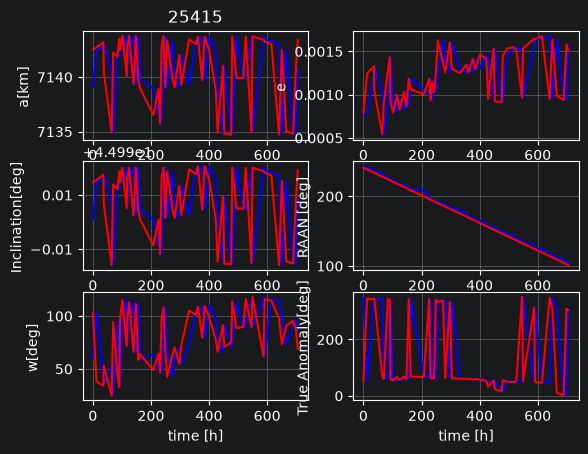

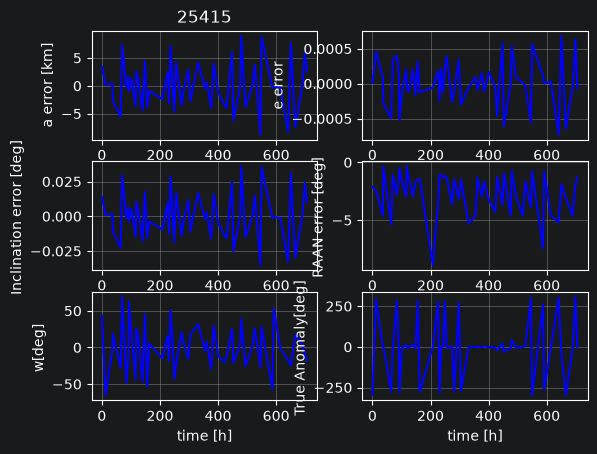

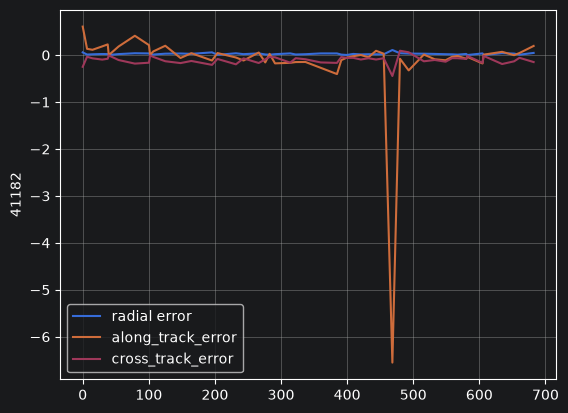

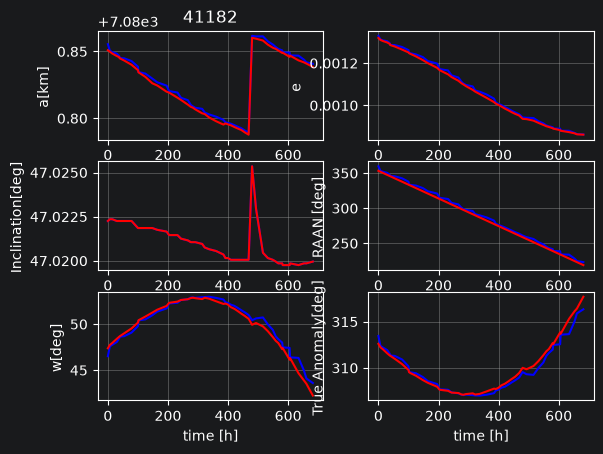

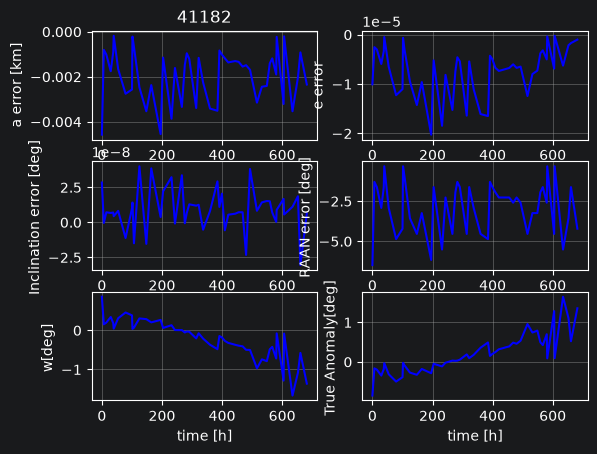

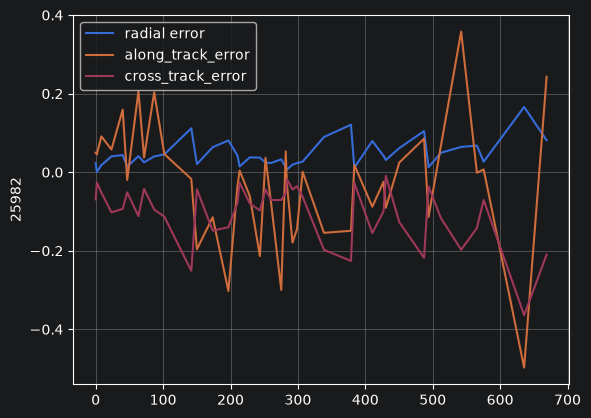

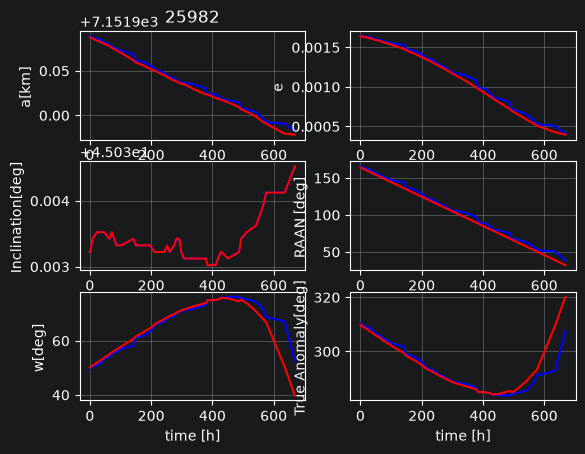

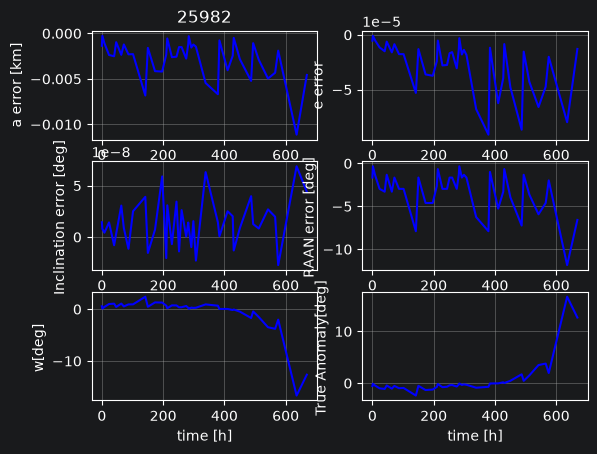

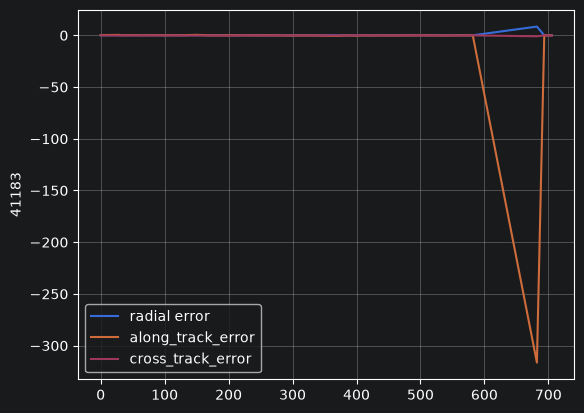

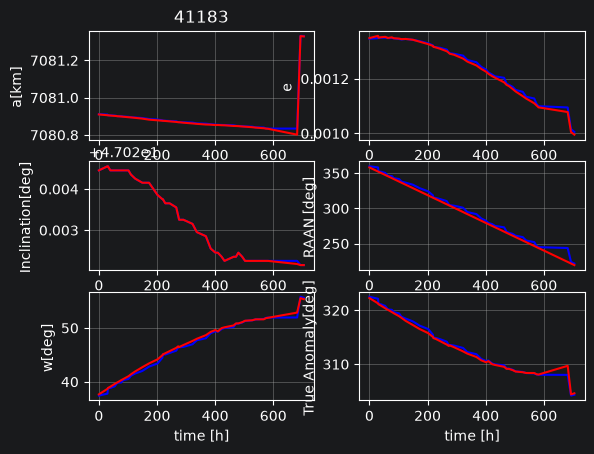

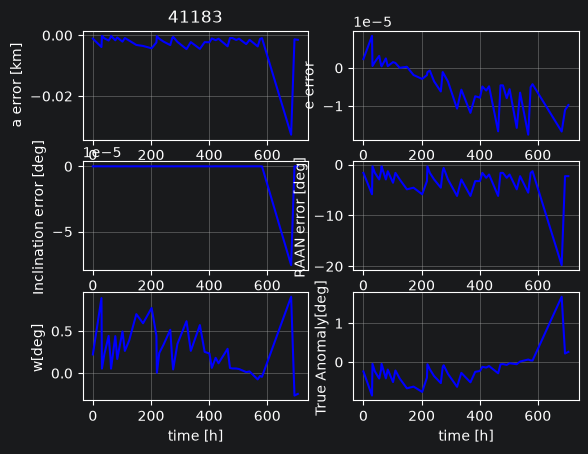

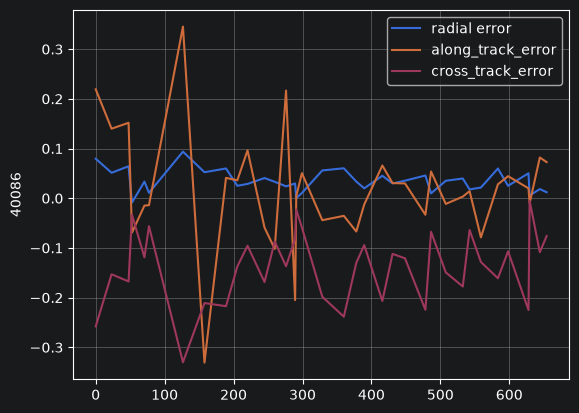

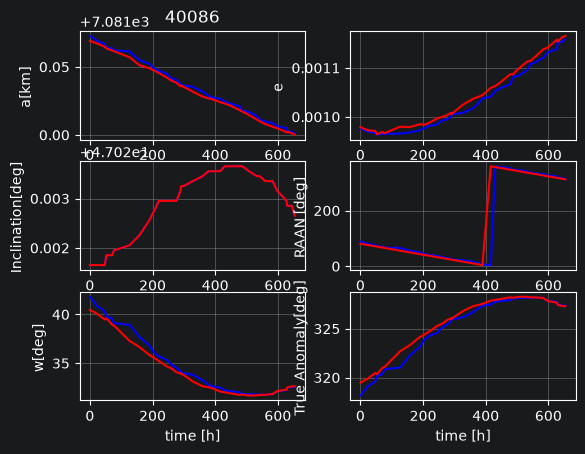

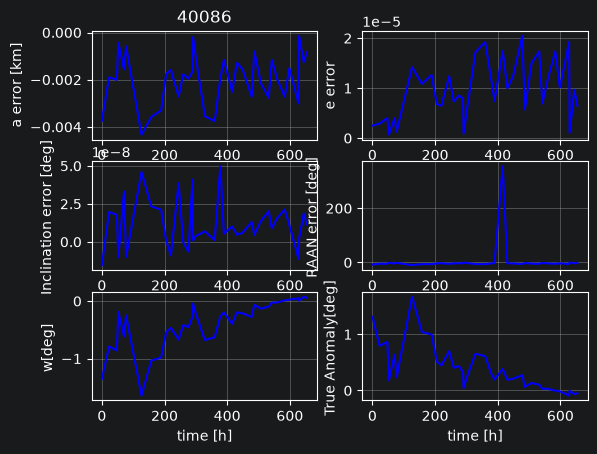

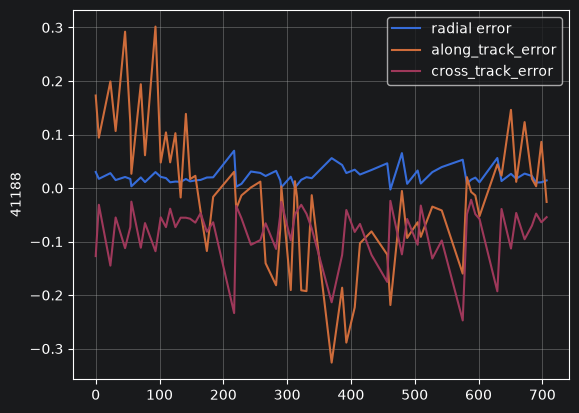

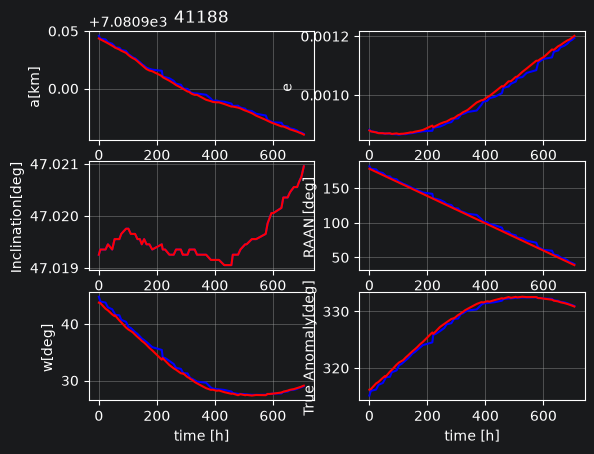

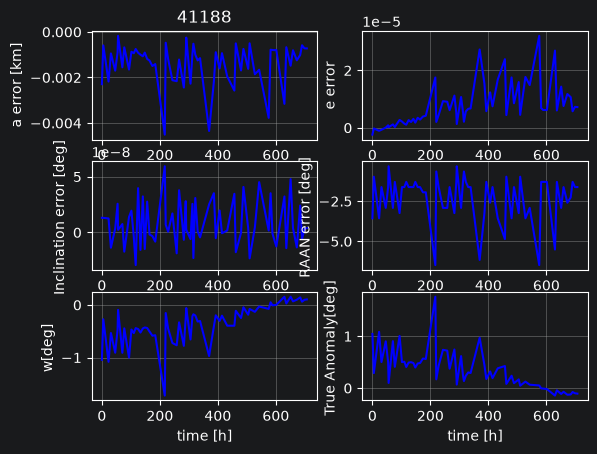

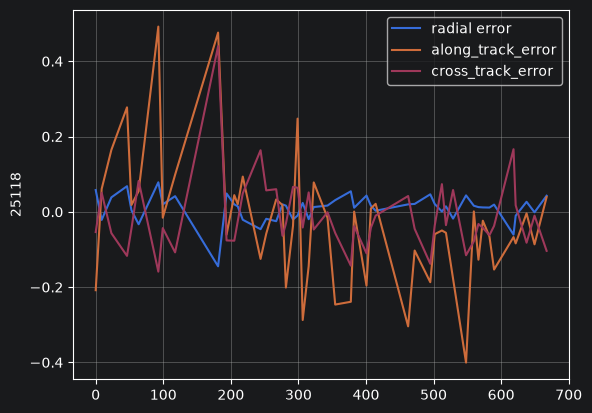

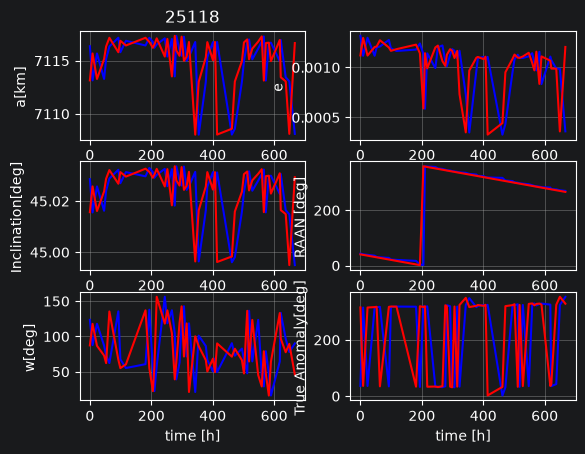

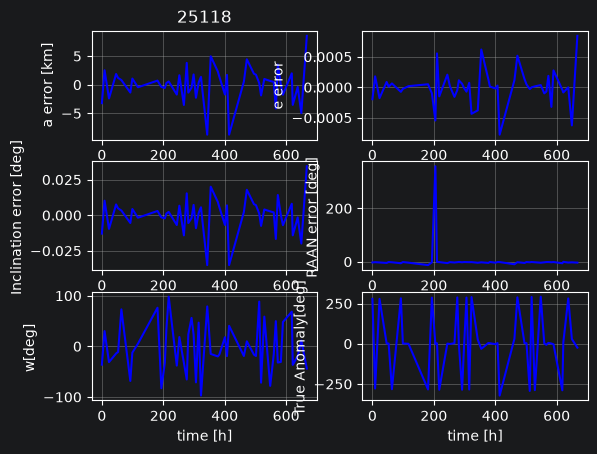

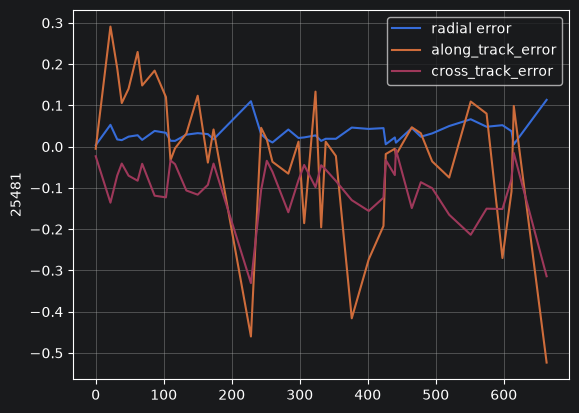

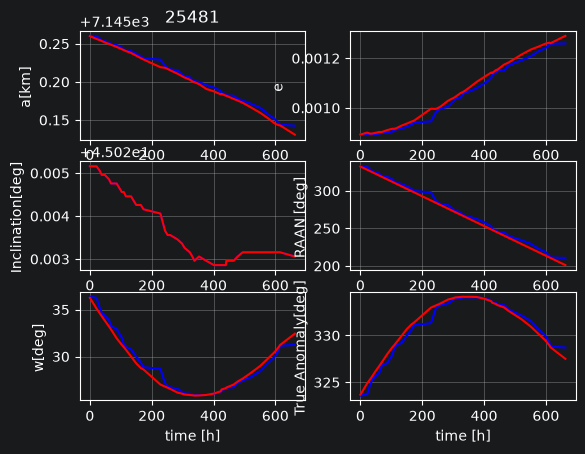

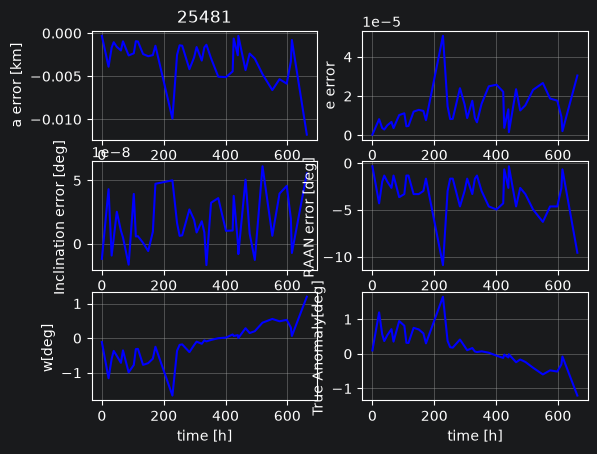

In [139]:
# calculate prediction errors
for isat  in range(len(sat_data_array_aug)):

    r_init = np.array(sat_data_array_aug[isat].r_init)
    r_pred = np.array(sat_data_array_aug[isat].r_pred)
    v_init = np.array(sat_data_array_aug[isat].v_init)
    v_pred = np.array(sat_data_array_aug[isat].v_pred)

    # 2. Vectorized subtraction: calculate all delta_r and delta_v at once
    delta_r = np.zeros([len(r_init)-1,3])
    r_init_arr= np.zeros([len(r_init)-1,3])
    r_pred_arr= np.zeros([len(r_pred)-1,3])
    v_init_arr = np.zeros([len(v_init)-1,3])
    v_pred_arr = np.zeros([len(v_pred)-1,3])
    for i in range(len(r_init)-1):
        for j in range(3):
            r_init_arr[i,j] = r_init[i][j]
            r_pred_arr[i,j] = r_pred[i][j]
            v_init_arr[i,j] = v_init[i][j]
            v_pred_arr[i,j] = v_pred[i][j]

    delta_r = r_init_arr [1:,:] - r_pred_arr [:-1,:]



    # 4. Construct the RSW / RTN Local Orbital Frame unit vectors from the reference state
    # R-axis: Radial (outward from Earth center along position vector)
    e_r = r_init_arr[1:,:]#-r_pred_arr[1:-1,:]
    e_r_norms = np.linalg.norm(e_r, axis=1, keepdims=True)
    e_r = e_r/e_r_norms
    #print(e_r_norms.shape)
    # W-axis (or N): Cross-track (normal to the orbital plane, along angular momentum)
    h = np.cross(r_init_arr[1:,:], v_init_arr[1:,:])
    e_w = h / np.linalg.norm(h,axis=1, keepdims=True)

    # S-axis: Along-track (perpendicular to R and W, aligned roughly with velocity)
    e_s = np.cross(e_w, e_r)

    # 5. Project the Cartesian error vector into the RSW frame
    radial_error = np.sum(delta_r * e_r , axis=1,keepdims=True)      # R: Radial error
    along_track_error = np.sum(delta_r*e_s,axis=1,keepdims=True)    # S: Along-track error
    cross_track_error = np.sum(delta_r*e_w,axis=1,keepdims=True)    # W: Cross-track error
    times_str= sat_data_array_filt[isat].EPOCH[1:-1]
    time_objs = pd.to_datetime(times_str)
    #time_objs=dt.datetime.fromisoformat(times_str)
    time_diffs = time_objs-time_objs.iloc[0]
    #delta_times_h = delta_times.total_seconds()/3600
    delta_times_h = [time_diffs.iloc[i].total_seconds()/3600 for i in  range(len(time_diffs))]

    fig,ax= plt.subplots()
    ax.plot(delta_times_h,radial_error,label='radial error')
    ax.plot(delta_times_h,along_track_error,label='along_track_error')
    ax.plot(delta_times_h,cross_track_error,label='cross_track_error')
    ax.legend()
    ax.grid(True)
    ax.set_ylabel(str(sat_data_array_filt[isat].NORAD_CAT_ID.iloc[0]))
    a_init_tab = []
    a_pred_tab=[]
    e_init_tab = []
    e_pred_tab=[]
    inc_init_tab = []
    inc_pred_tab=[]
    raan_init_tab = []
    raan_pred_tab=[]
    w_init_tab = []
    w_pred_tab=[]
    anomaly_init_tab = []
    anomaly_pred_tab=[]
    for i in  range(len(r_init_arr)-1):
        kepler_init=rv_to_kepler(r_init_arr[i], v_init_arr[i], mu=MU)
        kepler_pred=rv_to_kepler(r_pred_arr[i], v_pred_arr[i], mu=MU)

        a_init_tab.append(kepler_init["semi_major_axis_km"])
        a_pred_tab.append(kepler_pred["semi_major_axis_km"])
        e_init_tab.append(kepler_init["eccentricity"])
        e_pred_tab.append(kepler_pred["eccentricity"])
        inc_init_tab.append(kepler_init["inclination_deg"])
        inc_pred_tab.append(kepler_pred["inclination_deg"])
        raan_init_tab.append(kepler_init["raan_deg"])
        raan_pred_tab.append(kepler_pred["raan_deg"])
        w_init_tab.append(kepler_init["arg_perigee_deg"])
        w_pred_tab.append(kepler_pred["arg_perigee_deg"])
        anomaly_init_tab.append(kepler_init["true_anomaly_deg"])
        anomaly_pred_tab.append(kepler_pred["true_anomaly_deg"])
    fig,ax= plt.subplots(3,2)

    ax[0, 0].plot(delta_times_h,a_init_tab,color = 'blue')
    ax[0, 0].plot(delta_times_h,a_pred_tab,color = 'red')
    ax[0, 0].grid(True)
    ax[0, 0].set_xlabel('time [h]')
    ax[0, 0].set_ylabel('a[km] ')
    ax[0,0].set_title(str(sat_data_array_filt[isat].NORAD_CAT_ID.iloc[0]))

    ax[0, 1].plot(delta_times_h,e_init_tab,color = 'blue')
    ax[0, 1].plot(delta_times_h,e_pred_tab,color = 'red')
    ax[0, 1].grid(True)
    ax[0, 1].set_xlabel('time [h]')
    ax[0, 1].set_ylabel('e ')

    ax[1, 0].plot(delta_times_h,inc_init_tab,color = 'blue')
    ax[1, 0].plot(delta_times_h,inc_pred_tab,color = 'red')
    ax[1, 0].grid(True)
    ax[1, 0].set_xlabel('time [h]')
    ax[1, 0].set_ylabel('Inclination[deg] ')

    ax[1, 1].plot(delta_times_h,raan_init_tab,color = 'blue')
    ax[1, 1].plot(delta_times_h,raan_pred_tab,color = 'red')
    ax[1, 1].grid(True)
    ax[1, 1].set_xlabel('time [h]')
    ax[1, 1].set_ylabel('RAAN [deg] ')

    ax[2, 0].plot(delta_times_h,w_init_tab,color = 'blue')
    ax[2, 0].plot(delta_times_h,w_pred_tab,color = 'red')
    ax[2, 0].grid(True)
    ax[2, 0].set_xlabel('time [h]')
    ax[2, 0].set_ylabel('w[deg] ')

    ax[2, 1].plot(delta_times_h,anomaly_init_tab,color = 'blue')
    ax[2, 1].plot(delta_times_h,anomaly_pred_tab,color = 'red')
    ax[2, 1].grid(True)
    ax[2, 1].set_xlabel('time [h]')
    ax[2, 1].set_ylabel('True Anomaly[deg] ')

    fig,ax= plt.subplots(3,2)
    ax[0, 0].plot(delta_times_h,np.array(a_pred_tab)-np.array(a_init_tab),color = 'blue')
    ax[0, 0].grid(True)
    ax[0, 0].set_xlabel('time [h]')
    ax[0, 0].set_ylabel('a error [km]')
    ax[0,0].set_title(str(sat_data_array_filt[isat].NORAD_CAT_ID.iloc[0]))

    ax[0, 1].plot(delta_times_h,np.array(e_pred_tab)-np.array(e_init_tab),color = 'blue')
    ax[0, 1].grid(True)
    ax[0, 1].set_xlabel('time [h]')
    ax[0, 1].set_ylabel('e error')

    ax[1, 0].plot(delta_times_h,np.array(inc_pred_tab)-np.array(inc_init_tab),color = 'blue')
    ax[1, 0].grid(True)
    ax[1, 0].set_xlabel('time [h]')
    ax[1, 0].set_ylabel('Inclination error [deg] ')

    ax[1, 1].plot(delta_times_h,np.array(raan_pred_tab) -np.array(raan_init_tab),color = 'blue')
    ax[1, 1].grid(True)
    ax[1, 1].set_xlabel('time [h]')
    ax[1, 1].set_ylabel('RAAN error [deg] ')

    ax[2, 0].plot(delta_times_h,np.array(w_pred_tab) - np.array(w_init_tab),color = 'blue')
    ax[2, 0].grid(True)
    ax[2, 0].set_xlabel('time [h]')
    ax[2, 0].set_ylabel('w[deg] ')

    ax[2, 1].plot(delta_times_h,np.array(anomaly_pred_tab) - np.array(anomaly_init_tab),color = 'blue')
    ax[2, 1].grid(True)
    ax[2, 1].set_xlabel('time [h]')
    ax[2, 1].set_ylabel('True Anomaly[deg] ')



In [108]:
# check linearity
# perform sgp4 predictions

for isat  in range(len(sat_data_array_filt)):

    sat = sat_data_array_filt[isat].copy()
    for irow in range(len(sat)-1):
        date_str_init = sat.iloc[0].EPOCH
        date_str_pred = sat.iloc[irow+1].EPOCH
        sat_init_time = dt.datetime.fromisoformat(date_str_init).replace(tzinfo=dt.timezone.utc)
        sat_pred_time = dt.datetime.fromisoformat(date_str_pred).replace(tzinfo=dt.timezone.utc)
        epoch_1949 = dt.datetime(1949, 12, 31, 0, 0, tzinfo=dt.timezone.utc)
        delta_1949= sat_init_time - epoch_1949
        days_since_1949 = delta_1949.total_seconds() / 86400

        # 1. Parse mean motion derivatives correctly
        mm_dot = float(sat.iloc[0].MEAN_MOTION_DOT)
        mm_ddot = float(sat.iloc[0].MEAN_MOTION_DDOT)
        mm = float(sat.iloc[0].MEAN_MOTION)
        # 2. Convert TLE/OMM units to SGP4 native units (Revolutions/Day -> Radians/Minute)
        # 2pi / 1440 min = 0.004363323129985824
        ndot = mm_dot * (2 * math.pi / (1440.0 ** 2))
        nddot = mm_ddot * (2 * math.pi / (1440.0 ** 3))
        no_kozai = mm * (2 * math.pi / 1440.0)

        sat_pred = Satrec()
        sat_pred1= Satrec()
        sat_pred.sgp4init(
        WGS72,
        'i',
        int(sat.iloc[0].NORAD_CAT_ID),
        days_since_1949,
        sat.iloc[0].BSTAR,
        ndot,        # Corrected unit
        nddot,       # Corrected unit
        sat.iloc[0].ECCENTRICITY,
        math.radians(sat.iloc[0].ARG_OF_PERICENTER),
        math.radians(sat.iloc[0].INCLINATION),
        math.radians(sat.iloc[0].MEAN_ANOMALY),
        no_kozai,    # Corrected unit
        math.radians(sat.iloc[0].RA_OF_ASC_NODE),
    )
        sat_pred1.sgp4init(
        WGS72,
        'i',
        int(sat.iloc[irow].NORAD_CAT_ID),
        days_since_1949,
        sat.iloc[irow].BSTAR,
        ndot,        # Corrected unit
        nddot,       # Corrected unit
        sat.iloc[irow].ECCENTRICITY,
        math.radians(sat.iloc[irow].ARG_OF_PERICENTER),
        math.radians(sat.iloc[irow].INCLINATION),
        math.radians(sat.iloc[irow].MEAN_ANOMALY),
        no_kozai,    # Corrected unit
        math.radians(sat.iloc[irow].RA_OF_ASC_NODE),
    )
        jd_init, fr_init = jday(sat_init_time.year, sat_init_time.month, sat_init_time.day, sat_init_time.hour, sat_init_time.minute, sat_init_time.second)
        jd_pred, fr_pred = jday(sat_pred_time.year, sat_pred_time.month, sat_pred_time.day, sat_pred_time.hour, sat_pred_time.minute, sat_pred_time.second)
        e,r_init, v_init = sat_pred.sgp4(jd_init, fr_init)
        e,r_pred, v_pred = sat_pred.sgp4(jd_pred, fr_pred)
        e,r_true, v_true = sat_pred1.sgp4(jd_pred, fr_pred)
        #print(r_init, v_init)

        row_label = sat.index[irow]

        sat.at[row_label, 'r_init'] = tuple(r_init)
        sat.at[row_label, 'v_init'] = tuple(v_init)
        sat.at[row_label, 'r_pred'] = tuple(r_pred)
        sat.at[row_label, 'v_pred'] = tuple(v_pred)
        sat.at[row_label, 'r_true'] = tuple(r_true)
        sat.at[row_label, 'v_true'] = tuple(v_true)
    sat_data_array_filt[isat]=sat





KeyboardInterrupt: 

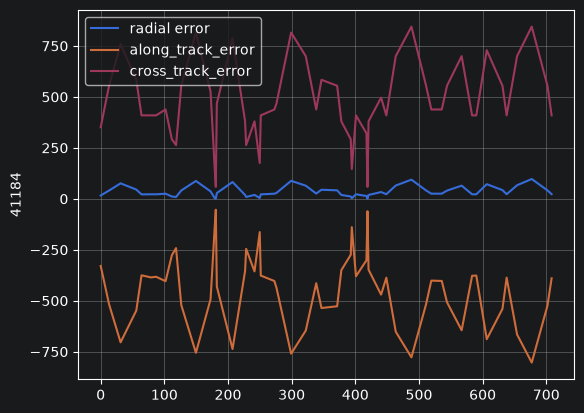

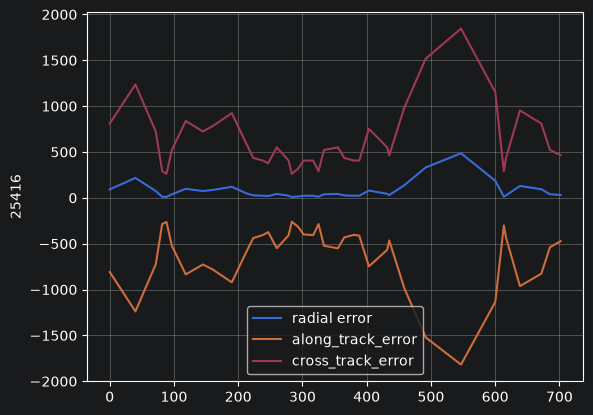

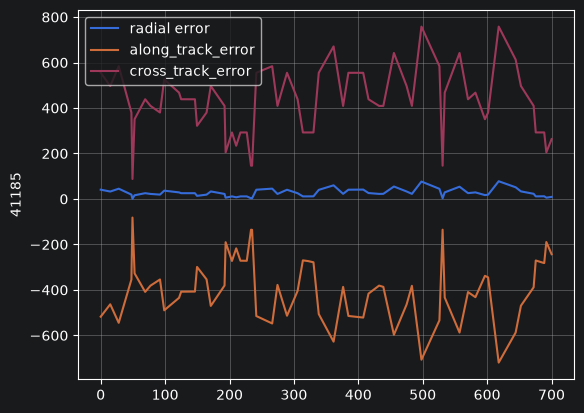

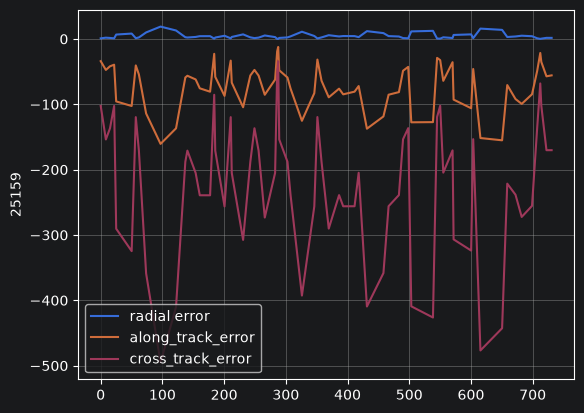

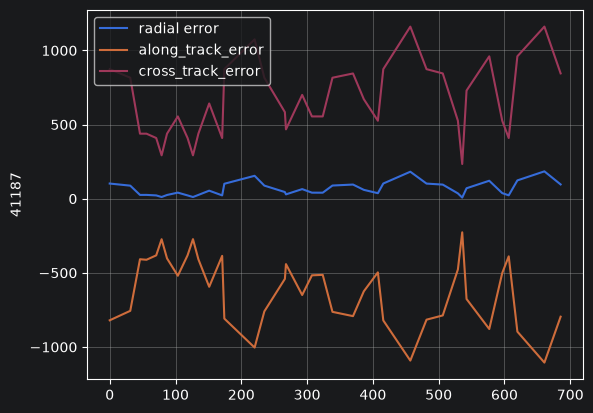

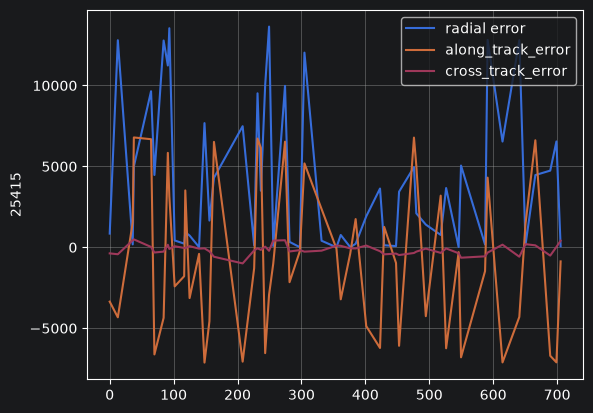

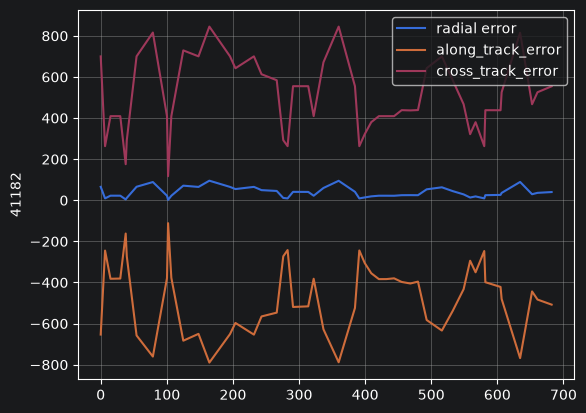

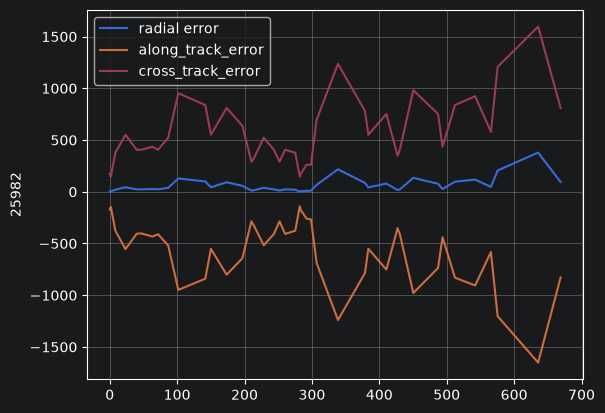

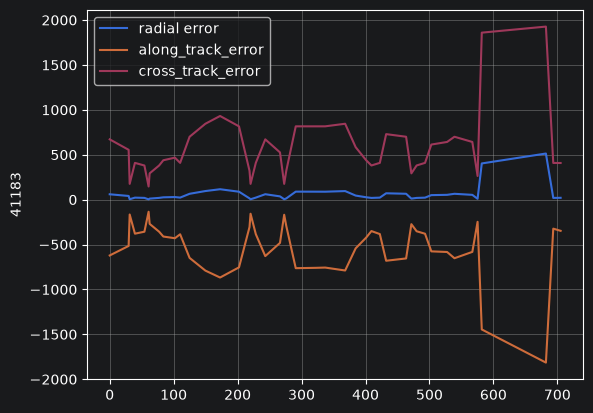

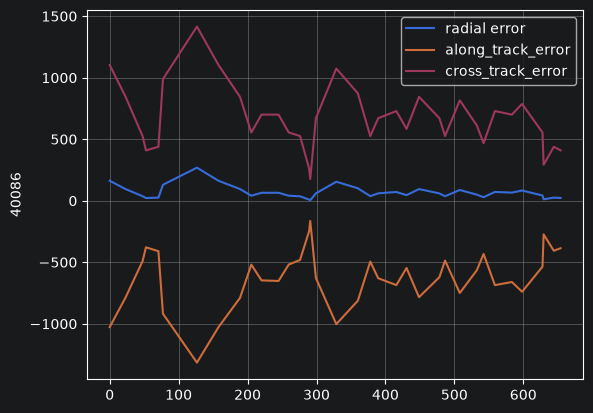

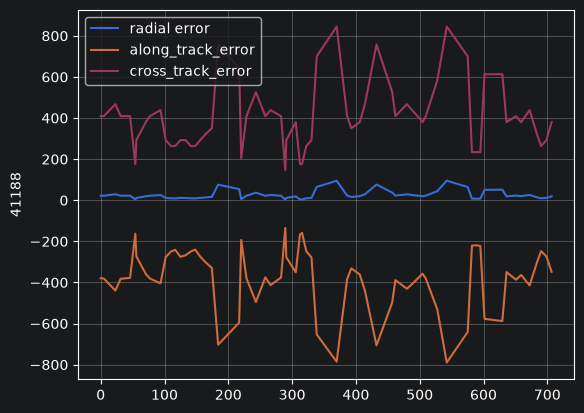

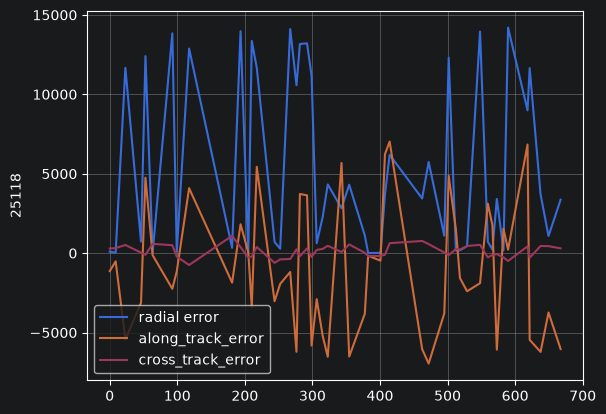

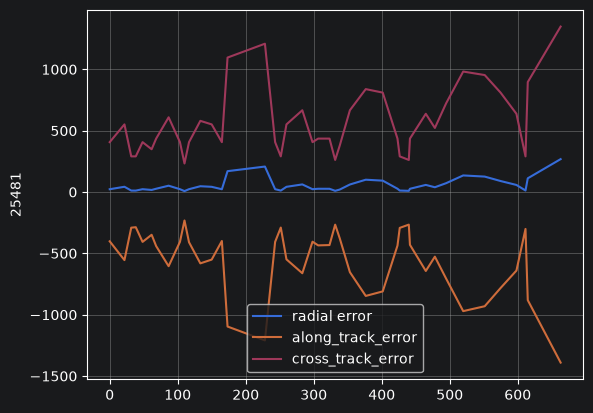

In [105]:
# calculate prediction errors
for isat  in range(len(sat_data_array_filt)):

    r_true = np.array(sat_data_array_filt[isat].r_true)
    r_pred = np.array(sat_data_array_filt[isat].r_pred)
    v_true = np.array(sat_data_array_filt[isat].v_true)
    v_pred = np.array(sat_data_array_filt[isat].v_pred)

    # 2. Vectorized subtraction: calculate all delta_r and delta_v at once
    delta_r = np.zeros([len(r_true)-1,3])
    r_true_arr= np.zeros([len(r_true)-1,3])
    r_pred_arr= np.zeros([len(r_pred)-1,3])
    v_true_arr = np.zeros([len(v_true)-1,3])
    for i in range(len(r_true)-1):
        for j in range(3):
            r_true_arr[i,j] = r_true[i][j]
            r_pred_arr[i,j] = r_true[i][j]
            v_true_arr[i,j] = v_true[i][j]

    delta_r = r_true_arr [1:,:] - r_pred_arr [:-1,:]

    # 4. Construct the RSW / RTN Local Orbital Frame unit vectors from the reference state
    # R-axis: Radial (outward from Earth center along position vector)
    e_r = r_true_arr[1:,:]
    e_r_norms = np.linalg.norm(e_r, axis=1, keepdims=True)
    e_r = e_r/e_r_norms
    #print(e_r_norms.shape)
    # W-axis (or N): Cross-track (normal to the orbital plane, along angular momentum)
    h = np.cross(r_true_arr[1:,:], v_true_arr[1:,:])
    e_w = h / np.linalg.norm(h,axis=1, keepdims=True)

    # S-axis: Along-track (perpendicular to R and W, aligned roughly with velocity)
    e_s = np.cross(e_w, e_r)

    # 5. Project the Cartesian error vector into the RSW frame
    radial_error = np.sum(delta_r * e_r , axis=1,keepdims=True)      # R: Radial error
    along_track_error = np.sum(delta_r*e_s,axis=1,keepdims=True)    # S: Along-track error
    cross_track_error = np.sum(delta_r*e_w,axis=1,keepdims=True)    # W: Cross-track error
    times_str= sat_data_array_filt[isat].EPOCH[1:-1]
    time_objs = pd.to_datetime(times_str)
    #time_objs=dt.datetime.fromisoformat(times_str)
    time_diffs = time_objs-time_objs.iloc[0]
    #delta_times_h = delta_times.total_seconds()/3600
    delta_times_h = [time_diffs.iloc[i].total_seconds()/3600 for i in  range(len(time_diffs))]
    #print(radial_error)
    #print(along_track_error)
    #print(cross_track_error)


    fig,ax= plt.subplots()
    ax.plot(delta_times_h,radial_error,label='radial error')
    ax.plot(delta_times_h,along_track_error,label='along_track_error')
    ax.plot(delta_times_h,cross_track_error,label='cross_track_error')
    ax.legend()
    ax.grid(True)
    ax.set_ylabel(str(sat_data_array_filt[isat].NORAD_CAT_ID.iloc[0]))
